# 15장. 제조 AI 모델의 시스템화

「AI로 만드는 제조공정 품질관리 따라하기」 15장 실습 Notebook입니다. CPU 런타임으로 충분합니다.
PoC 2(CMP 가상계측) 데이터를 씁니다. 7장 Notebook처럼 처음 실행 때 데이터를 내려받습니다.

실험 설계(결과를 보기 전에 정함)
- 모델: 9장과 같은 XGBoost를 시각 순 처음 40%(초기 학습)로 학습해 v1으로 저장
- 운영 재현: 나머지 60%를 시각 순으로 API에 보내 예측하고, 그룹마다 10장에 1장꼴로 실측값을 보냄(9장 every=10)
- 드리프트 점검: 매주 끝에 (1) 이번 주 실측 웨이퍼에서 운영 모델의 보정 전 MAE가 학습 때 교차검증 MAE의 1.5배 초과,
  (2) 감시 특징 4개 중 하나라도 PSI 0.25 초과 → 재학습 후보 생성
- 승인 조건: 지금까지 들어온 실측 웨이퍼를 시각 순으로 나눠, 앞 80%(+초기 학습)로 후보를 학습하고 뒤 20%에서
  후보 MAE가 운영 모델 MAE의 0.9배 이하일 때만 승인 요청. 승인은 사람이 하는 단계이며, 이 Notebook에서는 조건을
  만족하면 승인한 것으로 기록(시뮬레이션)

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/04-dashboard
    !pip install -q fastapi==0.165.0 httpx==0.28.1

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import shutil
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.vm_service as V

if V.REGISTRY.exists():                                  # 다시 실행할 때 처음부터 (모델 저장소·기록 초기화)
    shutil.rmtree(V.REGISTRY)
V.LOG_DB.unlink(missing_ok=True)

## 15-1. 모델 저장과 메타데이터

In [3]:
t0 = time.perf_counter()
init, stream, sensors, cols = V.prepare_data()
by_key = sensors.groupby(V.KEY)
print(f"데이터 준비 {time.perf_counter() - t0:.1f}초 | 초기 학습 {len(init)} | 운영 {len(stream)} | 특징 {len(cols)}")

데이터 준비 2.5초 | 초기 학습 1130 | 운영 1695 | 특징 88


In [4]:
path = V.train_artifact(init, cols, "cmp-xgb-v1", note="초기 모델: 시각 순 처음 40%")
V.promote("cmp-xgb-v1", approver="engineer1", reason="초기 운영 모델")
meta = json.loads((path / "meta.json").read_text(encoding="utf-8"))
print({k: meta[k] for k in ["version", "train_n", "cv_mae", "q90_by_group", "fit_sec", "env"]})
print("저장 파일:", {p.name: f"{p.stat().st_size / 1024:.0f}KB" for p in path.iterdir()})

{'version': 'cmp-xgb-v1', 'train_n': 1130, 'cv_mae': 2.5951, 'q90_by_group': {'A456': 4.7331, 'B': 5.031, 'A123': 5.0086}, 'fit_sec': 0.72, 'env': {'python': '3.12.9', 'sklearn': '1.9.1', 'xgboost': '3.4.1', 'pandas': '3.1.1', 'numpy': '2.5.5'}}
저장 파일: {'meta.json': '81KB', 'model.joblib': '957KB'}


In [5]:
# 저장한 모델을 다시 읽어 같은 예측이 나오는지, 읽는 데 얼마나 걸리는지
import joblib
from sklearn.base import clone

t0 = time.perf_counter()
loaded = joblib.load(path / "model.joblib")
load_ms = (time.perf_counter() - t0) * 1000
fresh = clone(V.make_models()["XGBoost"]).fit(init[cols], init["AVG_REMOVAL_RATE"])
same = np.allclose(loaded.predict(stream[cols]), fresh.predict(stream[cols]))
print(f"불러오기 {load_ms:.0f}ms | 다시 학습한 모델과 예측이 같은가: {same}")

불러오기 16ms | 다시 학습한 모델과 예측이 같은가: True


## 15-2. FastAPI 추론 서비스 시험

In [6]:
from fastapi.testclient import TestClient

from app.api import app

first = stream.iloc[0]
payload = {"wafer_id": str(first["WAFER_ID"]), "stage": first["STAGE"],
           "rows": V.sensor_payload(by_key, first["WAFER_ID"], first["STAGE"])}
print("요청 행 수:", len(payload["rows"]), "| 열:", list(payload["rows"][0])[:4], "...")

with TestClient(app) as client:
    health = client.get("/health").json()
    res = client.post("/predict", json=payload)
    print("health:", health)
    print("predict:", res.status_code, res.json(), "| 실제", first["AVG_REMOVAL_RATE"])

    bad = {}
    p = json.loads(json.dumps(payload)); del p["rows"][0]["SLURRY_FLOW_LINE_A"]
    bad["센서 열 누락"] = client.post("/predict", json=p)
    p = dict(payload, stage="C"); bad["단계 값 오류"] = client.post("/predict", json=p)
    p = dict(payload, rows=payload["rows"][:5]); bad["기록이 너무 짧음"] = client.post("/predict", json=p)
    bad["실측값 이상(4200)"] = client.post("/feedback", json={"wafer_id": payload["wafer_id"], "stage": "A", "actual": 4200})
    bad["예측 없는 웨이퍼"] = client.post("/feedback", json={"wafer_id": "NOPE", "stage": "A", "actual": 80})
    validation = {k: {"status": r.status_code, "detail": str(r.json()["detail"])[:120]} for k, r in bad.items()}
    for k, v in validation.items():
        print(f"{k:12s} → {v['status']} | {v['detail']}")

요청 행 수: 348 | 열: ['TIMESTAMP', 'CHAMBER', 'USAGE_OF_BACKING_FILM', 'USAGE_OF_DRESSER'] ...
health: {'status': 'ok', 'model_version': 'cmp-xgb-v1', 'cv_mae': 2.5951, 'train_n': 1130}
predict: 200 {'wafer_id': '-1714100520', 'stage': 'A', 'group': 'A456', 'model_version': 'cmp-xgb-v1', 'pred_raw': 73.0369, 'bias': 0.0, 'pred': 73.0369, 'interval_90': [68.3038, 77.77], 'out_of_range': ['USAGE_OF_DRESSER_TABLE_start'], 'latency_ms': 42.28} | 실제 70.3704
센서 열 누락      → 422 | [{'type': 'missing', 'loc': ['body', 'rows', 0, 'SLURRY_FLOW_LINE_A'], 'msg': 'Field required', 'input': {'TIMESTAMP': 4
단계 값 오류      → 422 | [{'type': 'string_pattern_mismatch', 'loc': ['body', 'stage'], 'msg': "String should match pattern '^(A|B)$'", 'input': 
기록이 너무 짧음    → 422 | [{'type': 'too_short', 'loc': ['body', 'rows'], 'msg': 'List should have at least 10 items after validation, not 5', 'in
실측값 이상(4200) → 422 | [{'type': 'less_than', 'loc': ['body', 'actual'], 'msg': 'Input should be less than 1000', 'input': 

In [7]:
# 처리 시간: TestClient(같은 프로세스)와 실제 HTTP 서버(uvicorn) 두 가지로 잰다
import subprocess

import httpx

def time_calls(post, n=100):
    lat = []
    for i in range(n):
        r = stream.iloc[i]
        body = {"wafer_id": str(r["WAFER_ID"]), "stage": r["STAGE"], "rows": V.sensor_payload(by_key, r["WAFER_ID"], r["STAGE"])}
        t = time.perf_counter(); resp = post(body); lat.append((time.perf_counter() - t) * 1000)
        assert resp.status_code == 200
    return {"median_ms": round(float(np.median(lat)), 1), "p95_ms": round(float(np.percentile(lat, 95)), 1)}

V.LOG_DB.unlink(missing_ok=True)
with TestClient(app) as client:
    latency = {"TestClient": time_calls(lambda b: client.post("/predict", json=b))}
    svc_ms = pd.read_sql("SELECT latency_ms FROM predictions", sqlite3.connect(V.LOG_DB))["latency_ms"]
latency["서비스 내부(특징+예측)"] = {"median_ms": round(float(svc_ms.median()), 1), "p95_ms": round(float(svc_ms.quantile(0.95)), 1)}

srv = subprocess.Popen([sys.executable, "-m", "uvicorn", "app.api:app", "--port", "8765", "--log-level", "warning"])
try:
    for _ in range(60):
        try:
            if httpx.get("http://127.0.0.1:8765/health", timeout=1).status_code == 200:
                break
        except httpx.HTTPError:
            time.sleep(0.5)
    with httpx.Client(base_url="http://127.0.0.1:8765", timeout=10) as hc:
        latency["uvicorn HTTP"] = time_calls(lambda b: hc.post("/predict", json=b))
finally:
    srv.terminate(); srv.wait()
print(latency)

{'TestClient': {'median_ms': 58.8, 'p95_ms': 62.0}, '서비스 내부(특징+예측)': {'median_ms': 37.7, 'p95_ms': 38.8}, 'uvicorn HTTP': {'median_ms': 57.5, 'p95_ms': 60.4}}


In [8]:
# 서비스 내부 시간을 단계별로: 특징 계산 vs 모델 예측
tf, tp, nrows = [], [], []
for i in range(100):
    r = stream.iloc[i]
    rows = V.sensor_payload(by_key, r["WAFER_ID"], r["STAGE"]); nrows.append(len(rows))
    t = time.perf_counter()
    s_ = pd.DataFrame(rows); s_["WAFER_ID"], s_["STAGE"] = str(r["WAFER_ID"]), r["STAGE"]
    f_ = V.add_group(V.extract_features(s_), s_); f_["grp_A123"] = (f_["grp"] == "A123").astype(int)
    tf.append((time.perf_counter() - t) * 1000)
    t = time.perf_counter(); loaded.predict(f_[meta["features"]]); tp.append((time.perf_counter() - t) * 1000)
latency["단계별 중앙값"] = {"features_ms": round(float(np.median(tf)), 1), "predict_ms": round(float(np.median(tp)), 1),
                         "rows_median": int(np.median(nrows))}
print(latency["단계별 중앙값"])

{'features_ms': 30.9, 'predict_ms': 6.8, 'rows_median': 339}


## 15-3. 운영 재현: 운영 기간 데이터를 API로 흘려보내기

In [9]:
def replay(client, stream, every=10, weekly_check=None):
    """시각 순으로 예측 요청을 보내고, 그룹마다 every장에 1장꼴로 실측값을 보낸다."""
    count, rows = {}, []
    stream = stream.assign(week=((stream["day"] - stream["day"].min()) // 7).astype(int))
    for w, wk in stream.groupby("week", sort=True):
        for _, r in wk.iterrows():
            body = {"wafer_id": str(r["WAFER_ID"]), "stage": r["STAGE"],
                    "rows": V.sensor_payload(by_key, r["WAFER_ID"], r["STAGE"])}
            out = client.post("/predict", json=body).json()
            c = count.get(r["grp"], 0); count[r["grp"]] = c + 1
            measured = c % every == 0
            if measured:
                client.post("/feedback", json={"wafer_id": body["wafer_id"], "stage": body["stage"],
                                               "actual": float(r["AVG_REMOVAL_RATE"])})
            rows.append({**out, "actual": float(r["AVG_REMOVAL_RATE"]), "measured": measured, "week": int(w),
                         "day": float(r["day"])})
        if weekly_check is not None:
            weekly_check(client, int(w), pd.DataFrame(rows))
    return pd.DataFrame(rows)

V.LOG_DB.unlink(missing_ok=True)
t0 = time.perf_counter()
with TestClient(app) as client:
    rep = replay(client, stream)
replay_sec = time.perf_counter() - t0
un = rep[~rep["measured"]]
static_result = {"n": len(rep), "measured": int(rep["measured"].sum()), "sec": round(replay_sec, 1),
                 "MAE_raw": round(float(np.mean(np.abs(un["actual"] - un["pred_raw"]))), 3),
                 "MAE_ewma": round(float(np.mean(np.abs(un["actual"] - un["pred"]))), 3),
                 "over_tol_ewma": round(float(np.mean(np.abs(un["actual"] - un["pred"]) > 5)), 3),
                 "interval_cover": round(float(np.mean((un["actual"] >= un["interval_90"].str[0]) & (un["actual"] <= un["interval_90"].str[1]))), 3),
                 "out_of_range_rate": round(float((rep["out_of_range"].str.len() > 0).mean()), 3)}
print(static_result, "| 9장 같은 정책: 보정 전 MAE 8.172, EWMA 보정 MAE 3.814")

{'n': 1695, 'measured': 171, 'sec': 120.6, 'MAE_raw': 8.172, 'MAE_ewma': 3.814, 'over_tol_ewma': 0.295, 'interval_cover': 0.7, 'out_of_range_rate': 1.0} | 9장 같은 정책: 보정 전 MAE 8.172, EWMA 보정 MAE 3.814


In [10]:
week_tab = rep.assign(err_raw=(rep["actual"] - rep["pred_raw"]).abs(), err=(rep["actual"] - rep["pred"]).abs())
weekly = week_tab.groupby("week").agg(n=("err", "size"), MAE_raw=("err_raw", "mean"), MAE_ewma=("err", "mean"),
                                      oor=("out_of_range", lambda s: (s.str.len() > 0).mean())).round(3)
print(weekly)

        n  MAE_raw  MAE_ewma  oor
week                             
0     309    6.243     3.571  1.0
1     357    9.799     3.121  1.0
2     370    7.936     4.563  1.0
3     373    7.476     4.198  1.0
4     221    8.704     3.614  1.0
5      65   11.938     3.158  1.0


## 15-4. 드리프트 점검·재학습 후보·승인 흐름

In [11]:
V.LOG_DB.unlink(missing_ok=True)
for d in V.REGISTRY.iterdir():                           # v1만 남기고 다시 시작
    if d.is_dir() and d.name != "cmp-xgb-v1":
        shutil.rmtree(d)
(V.REGISTRY / "registry.json").unlink()
V.promote("cmp-xgb-v1", approver="engineer1", reason="초기 운영 모델")

events = []
stream_w = stream.assign(week=((stream["day"] - stream["day"].min()) // 7).astype(int),
                         WID=stream["WAFER_ID"].astype(str))     # API에는 문자열로 보냈으므로 같은 형식으로 찾는다


def weekly_check(client, week, done):
    prod = client.get("/health").json()["model_version"]
    _, m = V.load_version(prod)
    wk = done[(done["week"] == week) & done["measured"] & (done["model_version"] == prod)]
    mae_raw = float(np.mean(np.abs(wk["actual"] - wk["pred_raw"]))) if len(wk) else float("nan")
    feats_w = stream_w[stream_w["week"] == week]
    psis = {c: round(V.psi(np.asarray(m["psi_reference"][c]), feats_w[c].to_numpy()), 2) for c in V.WATCH}
    reasons = []
    if mae_raw > 1.5 * m["cv_mae"]:
        reasons.append(f"실측 MAE {mae_raw:.2f} > 1.5×CV MAE {1.5 * m['cv_mae']:.2f}")
    over = [c for c, v in psis.items() if v > 0.25]
    if over:
        reasons.append("PSI > 0.25: " + ", ".join(over))
    ev = {"week": week, "production": prod, "n_feedback_week": int(len(wk)), "mae_raw_week": round(mae_raw, 3),
          "psi": psis, "triggered": bool(reasons), "reasons": reasons}
    if reasons:
        known = done[done["measured"]]                    # 지금까지 실측이 들어온 웨이퍼(시각 순)
        known_tab = stream_w.set_index(["WID", "STAGE"]).loc[list(zip(known["wafer_id"], known["stage"]))].reset_index()
        k = int(len(known_tab) * 0.8)
        fit_tab = pd.concat([init, known_tab.iloc[:k]], ignore_index=True)
        cmp_tab = known_tab.iloc[k:]
        ver = f"cmp-xgb-v{len([e for e in events if e.get('candidate')]) + 2}-cand"
        V.train_artifact(fit_tab, cols, ver, note=f"{week}주차 점검에서 생성")
        cand, _ = V.load_version(ver)
        prod_model, _ = V.load_version(prod)
        mae_c = float(np.mean(np.abs(cmp_tab["AVG_REMOVAL_RATE"] - cand.predict(cmp_tab[cols]))))
        mae_p = float(np.mean(np.abs(cmp_tab["AVG_REMOVAL_RATE"] - prod_model.predict(cmp_tab[cols]))))
        ok = mae_c <= 0.9 * mae_p
        ev.update(candidate=ver, n_fit=len(fit_tab), n_compare=len(cmp_tab), mae_candidate=round(mae_c, 3),
                  mae_production=round(mae_p, 3), approval_requested=ok)
        if ok:
            V.promote(ver, approver="engineer1 (시뮬레이션)",
                      reason=f"{week}주차: 최근 실측 {len(cmp_tab)}건에서 MAE {mae_p:.2f} → {mae_c:.2f}")
            ev["promoted"] = client.post("/reload").json()["model_version"]
    events.append(ev)
    print(ev)


t0 = time.perf_counter()
with TestClient(app) as client:
    rep2 = replay(client, stream, weekly_check=weekly_check)
flow_sec = time.perf_counter() - t0
un2 = rep2[~rep2["measured"]]
flow_result = {"MAE_raw": round(float(np.mean(np.abs(un2["actual"] - un2["pred_raw"]))), 3),
               "MAE_ewma": round(float(np.mean(np.abs(un2["actual"] - un2["pred"]))), 3),
               "over_tol_ewma": round(float(np.mean(np.abs(un2["actual"] - un2["pred"]) > 5)), 3),
               "sec": round(flow_sec, 1), "versions_used": rep2["model_version"].value_counts().to_dict()}
print("승인 흐름 적용:", flow_result)
print("고정 v1 + EWMA:", {k: static_result[k] for k in ["MAE_raw", "MAE_ewma", "over_tol_ewma"]})
print("9장 주간 무조건 재학습 + EWMA(every=10): MAE 4.196")
print(json.dumps(V.registry_state()["history"], ensure_ascii=False, indent=1))

{'week': 0, 'production': 'cmp-xgb-v1', 'n_feedback_week': 33, 'mae_raw_week': 5.422, 'psi': {'USAGE_OF_DRESSER_TABLE_start': 12.41, 'USAGE_OF_DRESSER_start': 7.58, 'SLURRY_FLOW_LINE_C_mean': 0.36, 'duration': 0.5}, 'triggered': True, 'reasons': ['실측 MAE 5.42 > 1.5×CV MAE 3.89', 'PSI > 0.25: USAGE_OF_DRESSER_TABLE_start, USAGE_OF_DRESSER_start, SLURRY_FLOW_LINE_C_mean, duration'], 'candidate': 'cmp-xgb-v2-cand', 'n_fit': 1156, 'n_compare': 7, 'mae_candidate': 3.984, 'mae_production': 9.39, 'approval_requested': True, 'promoted': 'cmp-xgb-v2-cand'}


{'week': 1, 'production': 'cmp-xgb-v2-cand', 'n_feedback_week': 35, 'mae_raw_week': 7.991, 'psi': {'USAGE_OF_DRESSER_TABLE_start': 12.43, 'USAGE_OF_DRESSER_start': 9.13, 'SLURRY_FLOW_LINE_C_mean': 0.55, 'duration': 1.27}, 'triggered': True, 'reasons': ['실측 MAE 7.99 > 1.5×CV MAE 3.62', 'PSI > 0.25: USAGE_OF_DRESSER_TABLE_start, USAGE_OF_DRESSER_start, SLURRY_FLOW_LINE_C_mean, duration'], 'candidate': 'cmp-xgb-v3-cand', 'n_fit': 1184, 'n_compare': 14, 'mae_candidate': 3.737, 'mae_production': 8.27, 'approval_requested': True, 'promoted': 'cmp-xgb-v3-cand'}


{'week': 2, 'production': 'cmp-xgb-v3-cand', 'n_feedback_week': 37, 'mae_raw_week': 6.027, 'psi': {'USAGE_OF_DRESSER_TABLE_start': 12.42, 'USAGE_OF_DRESSER_start': 4.05, 'SLURRY_FLOW_LINE_C_mean': 0.73, 'duration': 0.86}, 'triggered': True, 'reasons': ['실측 MAE 6.03 > 1.5×CV MAE 3.71', 'PSI > 0.25: USAGE_OF_DRESSER_TABLE_start, USAGE_OF_DRESSER_start, SLURRY_FLOW_LINE_C_mean, duration'], 'candidate': 'cmp-xgb-v4-cand', 'n_fit': 1214, 'n_compare': 21, 'mae_candidate': 4.725, 'mae_production': 5.028, 'approval_requested': False}


{'week': 3, 'production': 'cmp-xgb-v3-cand', 'n_feedback_week': 38, 'mae_raw_week': 4.007, 'psi': {'USAGE_OF_DRESSER_TABLE_start': 12.42, 'USAGE_OF_DRESSER_start': 9.11, 'SLURRY_FLOW_LINE_C_mean': 1.37, 'duration': 1.34}, 'triggered': True, 'reasons': ['실측 MAE 4.01 > 1.5×CV MAE 3.71', 'PSI > 0.25: USAGE_OF_DRESSER_TABLE_start, USAGE_OF_DRESSER_start, SLURRY_FLOW_LINE_C_mean, duration'], 'candidate': 'cmp-xgb-v5-cand', 'n_fit': 1244, 'n_compare': 29, 'mae_candidate': 3.934, 'mae_production': 3.799, 'approval_requested': False}


{'week': 4, 'production': 'cmp-xgb-v3-cand', 'n_feedback_week': 21, 'mae_raw_week': 3.753, 'psi': {'USAGE_OF_DRESSER_TABLE_start': 12.42, 'USAGE_OF_DRESSER_start': 7.91, 'SLURRY_FLOW_LINE_C_mean': 0.8, 'duration': 1.0}, 'triggered': True, 'reasons': ['실측 MAE 3.75 > 1.5×CV MAE 3.71', 'PSI > 0.25: USAGE_OF_DRESSER_TABLE_start, USAGE_OF_DRESSER_start, SLURRY_FLOW_LINE_C_mean, duration'], 'candidate': 'cmp-xgb-v6-cand', 'n_fit': 1261, 'n_compare': 33, 'mae_candidate': 4.744, 'mae_production': 4.068, 'approval_requested': False}


{'week': 5, 'production': 'cmp-xgb-v3-cand', 'n_feedback_week': 7, 'mae_raw_week': 3.763, 'psi': {'USAGE_OF_DRESSER_TABLE_start': 12.42, 'USAGE_OF_DRESSER_start': 10.87, 'SLURRY_FLOW_LINE_C_mean': 2.87, 'duration': 5.56}, 'triggered': True, 'reasons': ['실측 MAE 3.76 > 1.5×CV MAE 3.71', 'PSI > 0.25: USAGE_OF_DRESSER_TABLE_start, USAGE_OF_DRESSER_start, SLURRY_FLOW_LINE_C_mean, duration'], 'candidate': 'cmp-xgb-v7-cand', 'n_fit': 1266, 'n_compare': 35, 'mae_candidate': 4.913, 'mae_production': 4.199, 'approval_requested': False}
승인 흐름 적용: {'MAE_raw': 5.767, 'MAE_ewma': 4.031, 'over_tol_ewma': 0.322, 'sec': 148.0, 'versions_used': {'cmp-xgb-v3-cand': 1029, 'cmp-xgb-v2-cand': 357, 'cmp-xgb-v1': 309}}
고정 v1 + EWMA: {'MAE_raw': 8.172, 'MAE_ewma': 3.814, 'over_tol_ewma': 0.295}
9장 주간 무조건 재학습 + EWMA(every=10): MAE 4.196
[
 {
  "time": "2026-11-26T11:49:10",
  "from": null,
  "to": "cmp-xgb-v1",
  "approver": "engineer1",
  "reason": "초기 운영 모델"
 },
 {
  "time": "2026-11-26T11:49:37",
  "from": "

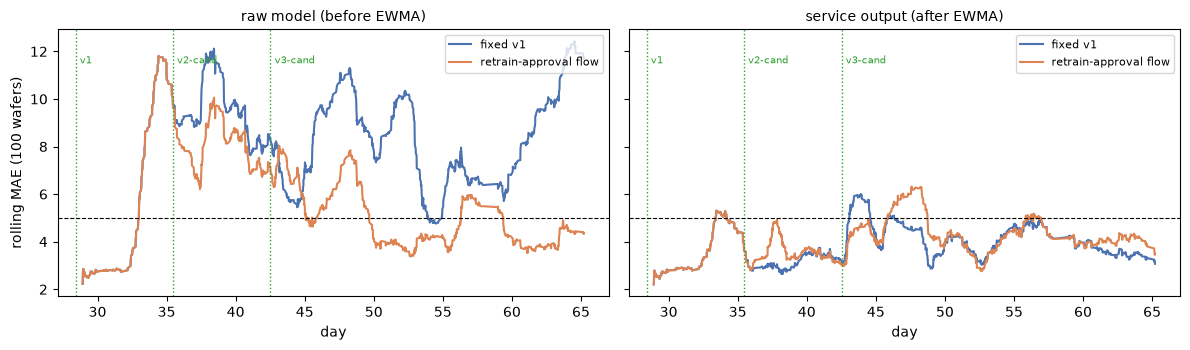

In [12]:
# 두 운영 방식의 오차 추이: 보정 전(모델 자체)과 EWMA 보정 후(서비스가 실제로 내는 값)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, col, title in [(axes[0], "pred_raw", "raw model (before EWMA)"), (axes[1], "pred", "service output (after EWMA)")]:
    for name, r, color in [("fixed v1", rep, "#4C72B0"), ("retrain-approval flow", rep2, "#DD8452")]:
        ax.plot(r["day"], (r["actual"] - r[col]).abs().rolling(100, min_periods=30).mean(), color=color, label=name)
    for v, g in rep2.groupby("model_version"):
        ax.axvline(g["day"].min(), color="tab:green", ls=":", lw=1)
        ax.text(g["day"].min() + 0.3, 11.5, v.replace("cmp-xgb-", ""), fontsize=7, color="tab:green")
    ax.axhline(5, color="k", ls="--", lw=0.8)
    ax.set_title(title, fontsize=10); ax.set_xlabel("day"); ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("rolling MAE (100 wafers)")
plt.tight_layout(); plt.savefig("results/15_replay.png", dpi=100); plt.show()

In [13]:
out = {"meta_v1": {k: meta[k] for k in ["version", "train_n", "cv_mae", "q90_by_group", "fit_sec", "env"]},
       "artifact_kb": {p.name: round(p.stat().st_size / 1024) for p in path.iterdir()},
       "load_ms": round(load_ms), "reload_same": bool(same),
       "health": health, "first_prediction": res.json(), "first_actual": float(first["AVG_REMOVAL_RATE"]),
       "validation": validation, "latency": latency,
       "static": static_result, "weekly": weekly.reset_index().to_dict("records"),
       "events": events, "flow": flow_result, "registry": V.registry_state()}
Path("results/15_service.json").write_text(json.dumps(out, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

8123